In [ ]:
# ============================================================
# 04_platform_eda.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
from pathlib import Path
from scipy.stats import spearmanr

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용
# ↑ KPI_REVPAR_ACTIVE_MEDIAN, KPI_DORMANT_RATIO, FEATURES_PATH, PROCESSED_DIR 포함

# ── 데이터 로드 (플랫폼 EDA용 — 피처 포함 데이터)
df    = load_features()
df_ao = load_features(active_only=True)

print(f"✅ 데이터 로드: {len(df):,}건 (Active+Oper: {len(df_ao):,}건)")
print(f"   자치구 수: {df['district'].nunique()}개")
print(f"   전체 Dormant 비율: {KPI_DORMANT_RATIO*100:.1f}%")

# 🗺️ 플랫폼 관점 EDA — 자치구별 RevPAR 분석

**분석 목적:** 25개 자치구의 RevPAR 성과 패턴을 분석합니다.

**탐색 가설:**
- H6: 공급 과잉 자치구(마포구)는 RevPAR 압박을 받는가?
- H7: POI 유형(관광지 vs 교통)에 따라 RevPAR 차이가 있는가?
- H8: 인구 밀집보다 관광 특화 자치구의 RevPAR가 높은가?
- H9: 비활성 비율(dormant_ratio)이 시장 건전성 지표인가?

## H6: 공급 집중 vs RevPAR 관계

In [3]:
# 자치구별 집계
district_agg = df.groupby("district").agg(
    total_listings=("ttm_revpar", "count"),
    ao_count=("is_active_operating", "sum"),
    median_revpar_ao=("ttm_revpar", lambda x: x[df.loc[x.index, "is_active_operating"]==1].median() if (df.loc[x.index, "is_active_operating"]==1).any() else 0),
    dormant_count=("refined_status", lambda x: x.isin(["Dormant","Ghost"]).sum()),
    superhost_rate=("superhost", "mean"),
    median_pop=("ttm_pop", "median")
).reset_index()
district_agg["dormant_ratio"] = district_agg["dormant_count"] / district_agg["total_listings"]
district_agg["supply_share"] = district_agg["total_listings"] / district_agg["total_listings"].sum()
print("RevPAR 상위 10개 자치구:")
print(district_agg[["district","total_listings","median_revpar_ao","dormant_ratio"]].sort_values("median_revpar_ao", ascending=False).head(10).to_string(index=False))

RevPAR 상위 10개 자치구:
    district  total_listings  median_revpar_ao  dormant_ratio
     Mapo-gu            6699          63365.50       0.506941
  Yongsan-gu            2870          58082.80       0.512195
   Jongno-gu            2640          54514.55       0.460985
Seongdong-gu             579          53493.85       0.588946
  Gangnam-gu            3097          53051.60       0.615111
     Jung-gu            3589          52939.00       0.520479
   Seocho-gu            1596          50898.85       0.614662
   Songpa-gu            1034          49550.50       0.603482
 Gwangjin-gu             816          44277.55       0.490196
    Nowon-gu             194          39073.90       0.597938


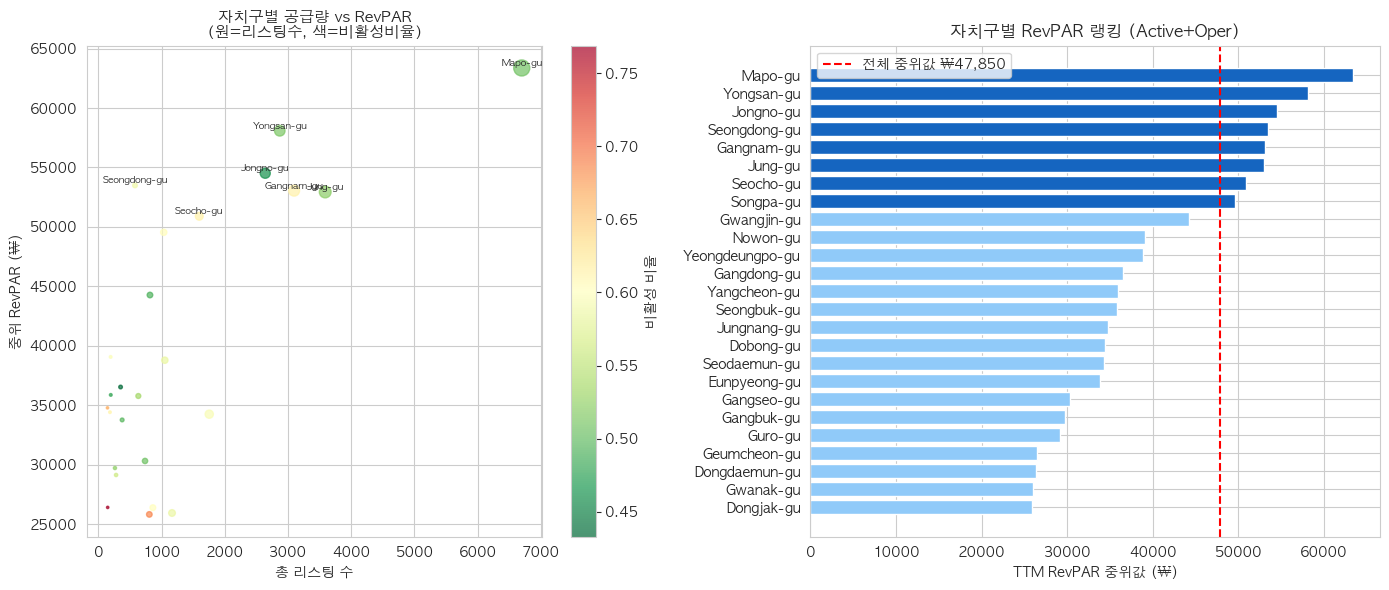

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sc = axes[0].scatter(district_agg["total_listings"], district_agg["median_revpar_ao"],
                      s=district_agg["total_listings"]/50, alpha=0.7,
                      c=district_agg["dormant_ratio"], cmap="RdYlGn_r")
for _, row in district_agg.iterrows():
    if row["total_listings"] > 3000 or row["median_revpar_ao"] > 50000:
        axes[0].annotate(row["district"], (row["total_listings"], row["median_revpar_ao"]), fontsize=7, ha="center", va="bottom")
plt.colorbar(sc, ax=axes[0], label="비활성 비율")
axes[0].set_title("자치구별 공급량 vs RevPAR\n(원=리스팅수, 색=비활성비율)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("총 리스팅 수"); axes[0].set_ylabel("중위 RevPAR (₩)")

top_d = district_agg.sort_values("median_revpar_ao", ascending=True)
colors_r = ["#1565C0" if v >= KPI_REVPAR_ACTIVE_MEDIAN else "#90CAF9" for v in top_d["median_revpar_ao"]]
axes[1].barh(top_d["district"], top_d["median_revpar_ao"], color=colors_r)
axes[1].axvline(KPI_REVPAR_ACTIVE_MEDIAN, color="red", linestyle="--", label=f"전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}")
axes[1].set_title("자치구별 RevPAR 랭킹 (Active+Oper)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("TTM RevPAR 중위값 (₩)"); axes[1].legend()
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_04_district_supply_revpar.png", dpi=100, bbox_inches="tight")
plt.show()

## H7: POI 유형별 RevPAR 분석

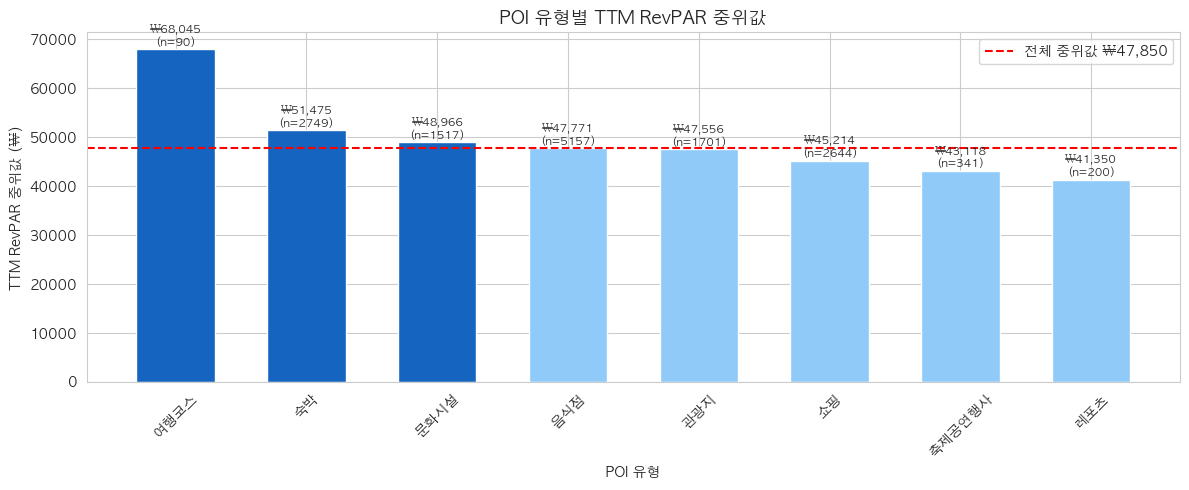

In [5]:
if "nearest_poi_type_name" in df_ao.columns:
    poi_stats = df_ao.groupby("nearest_poi_type_name")["ttm_revpar"].agg(median="median", count="count").sort_values("median", ascending=False)
    poi_stats = poi_stats[poi_stats["count"] >= 10]
    fig, ax = plt.subplots(figsize=(12, 5))
    colors_p = ["#1565C0" if v >= KPI_REVPAR_ACTIVE_MEDIAN else "#90CAF9" for v in poi_stats["median"]]
    bars = ax.bar(poi_stats.index, poi_stats["median"], color=colors_p, width=0.6)
    ax.axhline(KPI_REVPAR_ACTIVE_MEDIAN, color="red", linestyle="--", label=f"전체 중위값 ₩{KPI_REVPAR_ACTIVE_MEDIAN:,.0f}")
    ax.set_title("POI 유형별 TTM RevPAR 중위값", fontsize=13, fontweight="bold")
    ax.set_ylabel("TTM RevPAR 중위값 (₩)"); ax.set_xlabel("POI 유형")
    for bar, row in zip(bars, poi_stats.itertuples()):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+300, f"₩{row.median:,.0f}\n(n={row.count})", ha="center", va="bottom", fontsize=8)
    ax.tick_params(axis="x", rotation=45); ax.legend()
    plt.tight_layout()
    plt.savefig(REPORTS_DIR / "fig_04_poi_type_revpar.png", dpi=100, bbox_inches="tight")
    plt.show()
else:
    print("nearest_poi_type_name 컬럼 없음")

## H8: 인구 vs RevPAR 관계

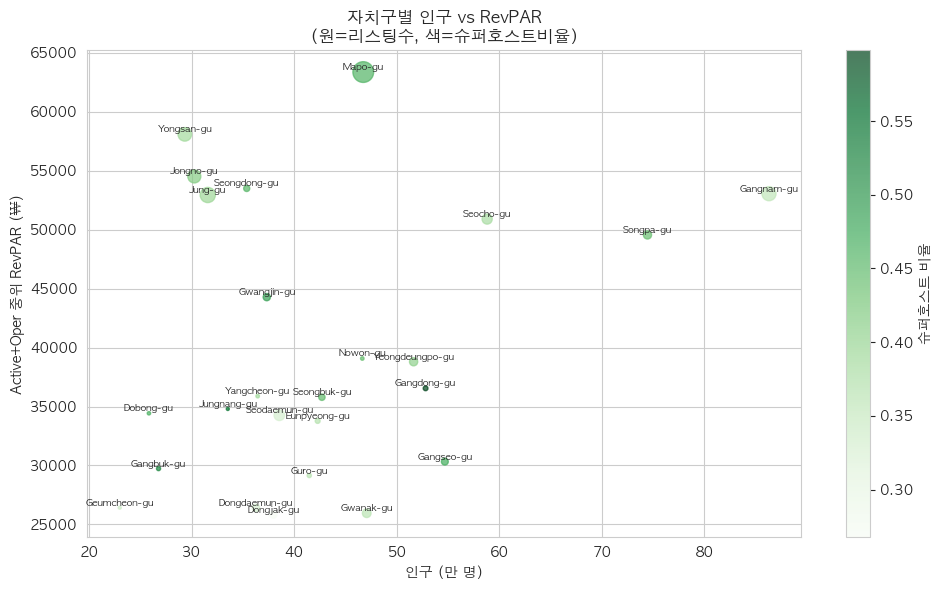

인구 vs RevPAR Spearman rho=0.122 (p=0.5628)
→ 고인구 자치구가 반드시 고RevPAR는 아님


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(district_agg["median_pop"]/10000, district_agg["median_revpar_ao"],
                 s=district_agg["total_listings"]/30, alpha=0.7,
                 c=district_agg["superhost_rate"], cmap="Greens")
for _, row in district_agg.iterrows():
    ax.annotate(row["district"], (row["median_pop"]/10000, row["median_revpar_ao"]), fontsize=7, ha="center", va="bottom")
plt.colorbar(sc, ax=ax, label="슈퍼호스트 비율")
ax.set_title("자치구별 인구 vs RevPAR\n(원=리스팅수, 색=슈퍼호스트비율)", fontsize=12, fontweight="bold")
ax.set_xlabel("인구 (만 명)"); ax.set_ylabel("Active+Oper 중위 RevPAR (₩)")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_04_population_revpar.png", dpi=100, bbox_inches="tight")
plt.show()
r, p = spearmanr(district_agg["median_pop"], district_agg["median_revpar_ao"])
print(f"인구 vs RevPAR Spearman rho={r:.3f} (p={p:.4f})")
print("→ 고인구 자치구가 반드시 고RevPAR는 아님")

## H9: 비활성 비율과 시장 건전성

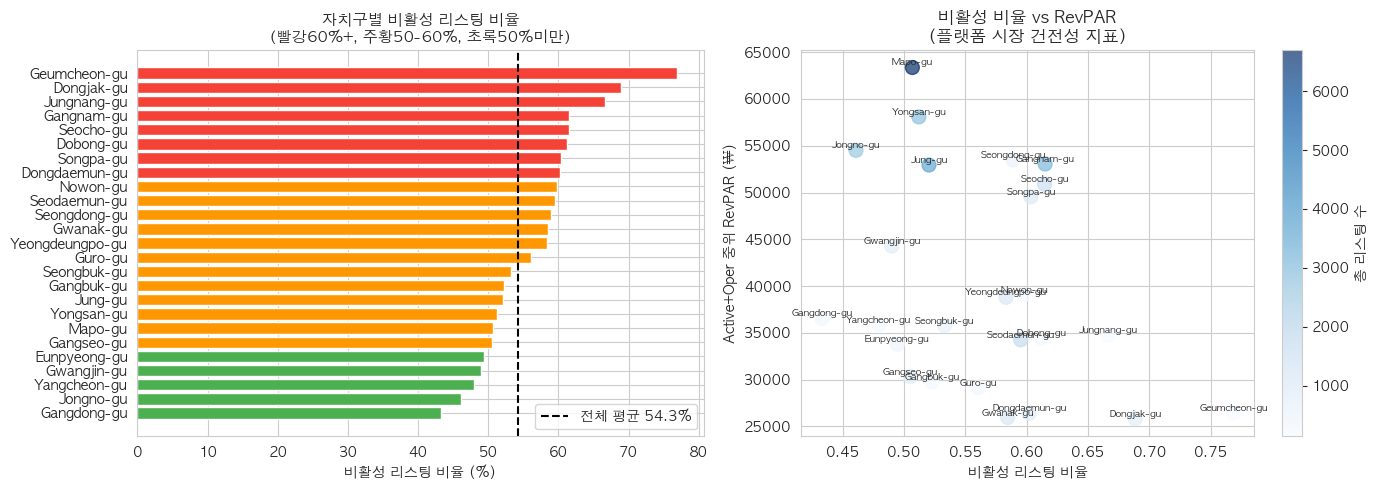

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d_sorted = district_agg.sort_values("dormant_ratio", ascending=True)
colors_d = ["#F44336" if v > 0.6 else "#FF9800" if v > 0.5 else "#4CAF50" for v in d_sorted["dormant_ratio"]]
axes[0].barh(d_sorted["district"], d_sorted["dormant_ratio"]*100, color=colors_d)
axes[0].axvline(KPI_DORMANT_RATIO*100, color="black", linestyle="--", label=f"전체 평균 {KPI_DORMANT_RATIO*100:.1f}%")
axes[0].set_title("자치구별 비활성 리스팅 비율\n(빨강60%+, 주황50-60%, 초록50%미만)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("비활성 리스팅 비율 (%)"); axes[0].legend()

sc2 = axes[1].scatter(district_agg["dormant_ratio"], district_agg["median_revpar_ao"],
                       s=100, alpha=0.7, c=district_agg["total_listings"], cmap="Blues")
for _, row in district_agg.iterrows():
    axes[1].annotate(row["district"], (row["dormant_ratio"], row["median_revpar_ao"]), fontsize=7, ha="center", va="bottom")
plt.colorbar(sc2, ax=axes[1], label="총 리스팅 수")
axes[1].set_title("비활성 비율 vs RevPAR\n(플랫폼 시장 건전성 지표)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("비활성 리스팅 비율"); axes[1].set_ylabel("Active+Oper 중위 RevPAR (₩)")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_04_dormant_revpar.png", dpi=100, bbox_inches="tight")
plt.show()

In [8]:
district_agg.to_csv(PROCESSED_DIR / "district_aggregated.csv", index=False, encoding="utf-8-sig")
print("✅ 자치구 집계 데이터 저장: data/processed/district_aggregated.csv")
r2, p2 = spearmanr(district_agg["dormant_ratio"], district_agg["median_revpar_ao"])
print(f"\n비활성비율 vs RevPAR Spearman rho={r2:.3f} (p={p2:.4f})")
print(district_agg[["district","total_listings","median_revpar_ao","dormant_ratio"]].sort_values("median_revpar_ao", ascending=False).to_string(index=False))

✅ 자치구 집계 데이터 저장: data/processed/district_aggregated.csv

비활성비율 vs RevPAR Spearman rho=-0.288 (p=0.1632)
       district  total_listings  median_revpar_ao  dormant_ratio
        Mapo-gu            6699          63365.50       0.506941
     Yongsan-gu            2870          58082.80       0.512195
      Jongno-gu            2640          54514.55       0.460985
   Seongdong-gu             579          53493.85       0.588946
     Gangnam-gu            3097          53051.60       0.615111
        Jung-gu            3589          52939.00       0.520479
      Seocho-gu            1596          50898.85       0.614662
      Songpa-gu            1034          49550.50       0.603482
    Gwangjin-gu             816          44277.55       0.490196
       Nowon-gu             194          39073.90       0.597938
Yeongdeungpo-gu            1051          38798.55       0.583254
    Gangdong-gu             351          36543.90       0.433048
   Yangcheon-gu             196          35881.10  